# Experiment 8: Time Series Forecasting and Trend Lines

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import ExponentialSmoothing

In [2]:
dates = pd.date_range(start='2024-01-01', periods=24, freq='MS')
sales = [
    120, 125, 132, 128, 140, 148, 155, 160, 158, 170, 182, 195,
    188, 194, 205, 201, 215, 224, 232, 240, 238, 252, 265, 280
]
df = pd.DataFrame({'Date': dates, 'Sales': sales})
df['Moving_Avg_3M'] = df['Sales'].rolling(window=3).mean()
print(df.head(10))

        Date  Sales  Moving_Avg_3M
0 2024-01-01    120            NaN
1 2024-02-01    125            NaN
2 2024-03-01    132     125.666667
3 2024-04-01    128     128.333333
4 2024-05-01    140     133.333333
5 2024-06-01    148     138.666667
6 2024-07-01    155     147.666667
7 2024-08-01    160     154.333333
8 2024-09-01    158     157.666667
9 2024-10-01    170     162.666667


In [3]:
x_num = np.arange(len(df))
slope, intercept = np.polyfit(x_num, df['Sales'], 1)
df['Trend_Line'] = slope * x_num + intercept
print("Trend Slope:", round(slope, 2))

Trend Slope: 6.57


In [4]:
model = ExponentialSmoothing(df['Sales'], trend='add', seasonal=None)
fit = model.fit()
forecast_values = fit.forecast(6)
future_dates = pd.date_range(start='2026-01-01', periods=6, freq='MS')
forecast_df = pd.DataFrame({'Date': future_dates, 'Forecast': np.round(forecast_values.values, 2)})
print(forecast_df)

        Date  Forecast
0 2026-01-01    277.72
1 2026-02-01    286.03
2 2026-03-01    294.35
3 2026-04-01    302.66
4 2026-05-01    310.98
5 2026-06-01    319.29


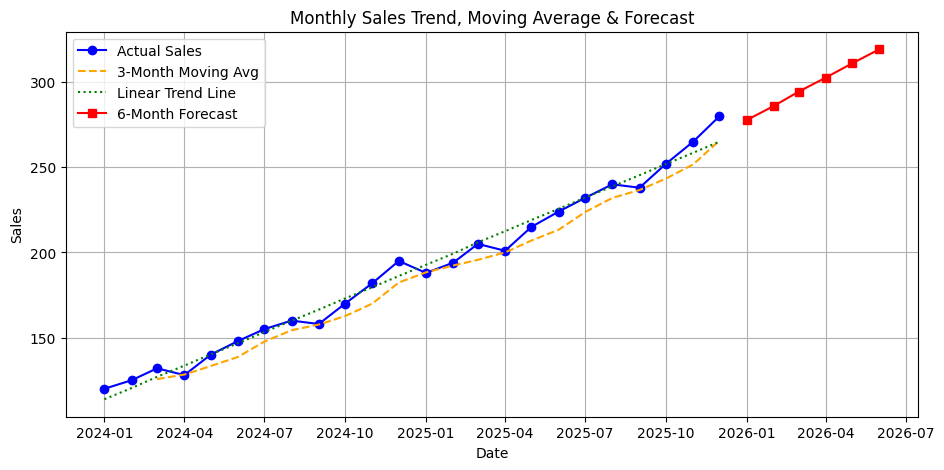

In [5]:
plt.figure(figsize=(11, 5))
plt.plot(df['Date'], df['Sales'], marker='o', label='Actual Sales', color='blue')
plt.plot(df['Date'], df['Moving_Avg_3M'], linestyle='--', label='3-Month Moving Avg', color='orange')
plt.plot(df['Date'], df['Trend_Line'], linestyle=':', label='Linear Trend Line', color='green')
plt.plot(forecast_df['Date'], forecast_df['Forecast'], marker='s', label='6-Month Forecast', color='red')
plt.title('Monthly Sales Trend, Moving Average & Forecast')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.legend()
plt.grid(True)
plt.show()